Yearly Release Counts (First 5 rows):
type          Movie  TV Show
release_year                
1925              0        1
1942              2        0
1943              3        0
1944              3        0
1945              3        1


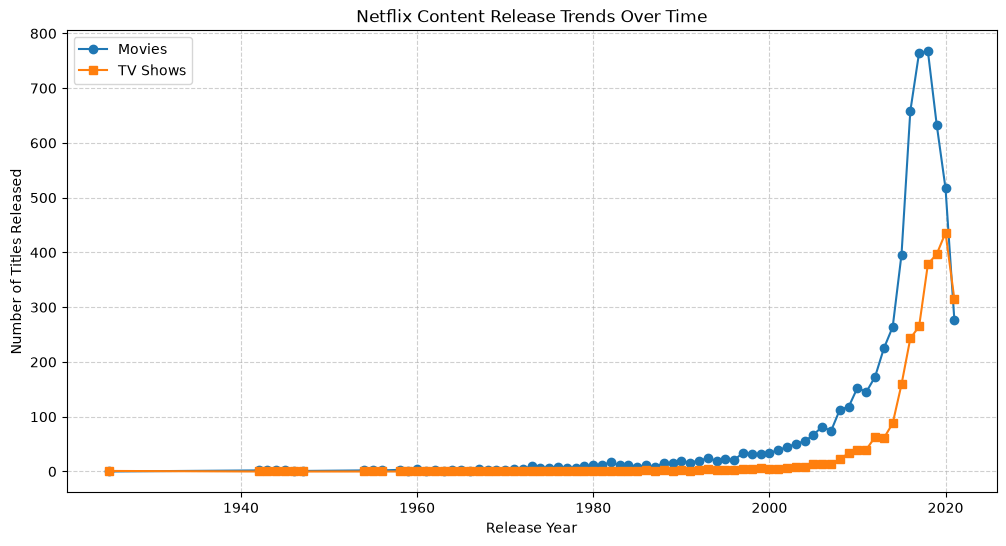

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the data
df = pd.read_csv('Dataset.csv')

# 2. Drop rows with missing release_year
df = df.dropna(subset=['release_year'])

# 3. Convert release_year to integer (sometimes it loads as float)
df['release_year'] = df['release_year'].astype(int)

# 4. Aggregate: Count the number of titles released per year, separated by type
yearly_counts = df.groupby(['release_year', 'type']).size().unstack(fill_value=0)

# 5. Let's look at the data
print("Yearly Release Counts (First 5 rows):")
print(yearly_counts.head())

# 6. Plot the historical trend
plt.figure(figsize=(12, 6))
plt.plot(yearly_counts.index, yearly_counts['Movie'], label='Movies', marker='o')
plt.plot(yearly_counts.index, yearly_counts['TV Show'], label='TV Shows', marker='s')
plt.title('Netflix Content Release Trends Over Time')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles Released')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

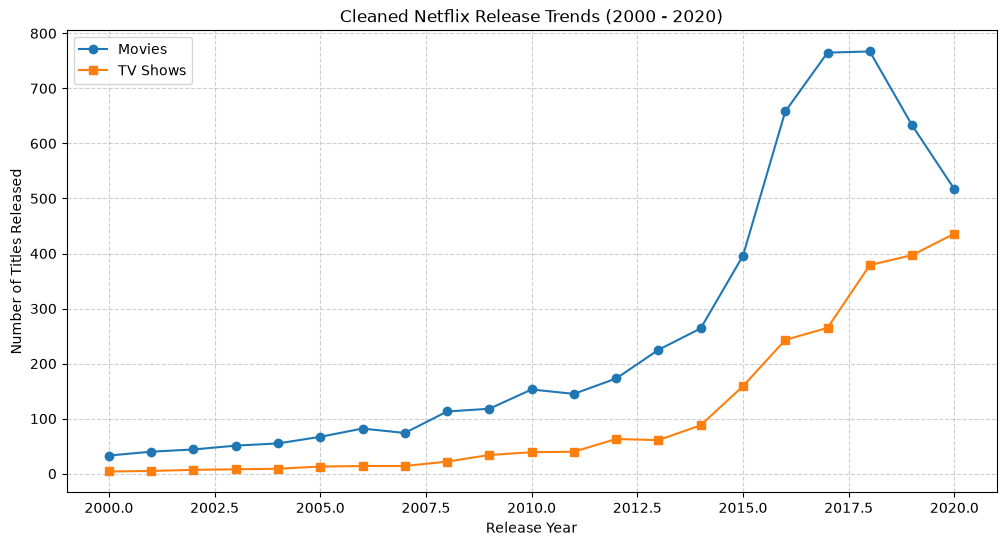

In [2]:
# 1. Filter the data to start from 2000 to remove the sparse historical data
yearly_counts_clean = yearly_counts[yearly_counts.index >= 2000].copy()

# 2. Drop the year 2021 because it's incomplete (the "2021 Trap")
yearly_counts_clean = yearly_counts_clean[yearly_counts_clean.index < 2021]

# 3. Plot the cleaned data
plt.figure(figsize=(12, 6))
plt.plot(yearly_counts_clean.index, yearly_counts_clean['Movie'], label='Movies', marker='o')
plt.plot(yearly_counts_clean.index, yearly_counts_clean['TV Show'], label='TV Shows', marker='s')
plt.title('Cleaned Netflix Release Trends (2000 - 2020)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles Released')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [3]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings('ignore') # Ignore convergence warnings

# 1. Prepare the training data
# We just want the 'Movie' column and the year as the index
movie_series = yearly_counts_clean['Movie']

# 2. Train the ARIMA model
# (p,d,q) = (1,1,1) is a standard starting point for trending data
model = ARIMA(movie_series, order=(1, 1, 1))
model_fit = model.fit()

# 3. Forecast the next 3 years (2021, 2022, 2023)
forecast = model_fit.forecast(steps=3)
print("Forecasted Movies for 2021, 2022, 2023:")
print(forecast)

Forecasted Movies for 2021, 2022, 2023:
21    457.073501
22    427.406737
23    412.720131
Name: predicted_mean, dtype: float64


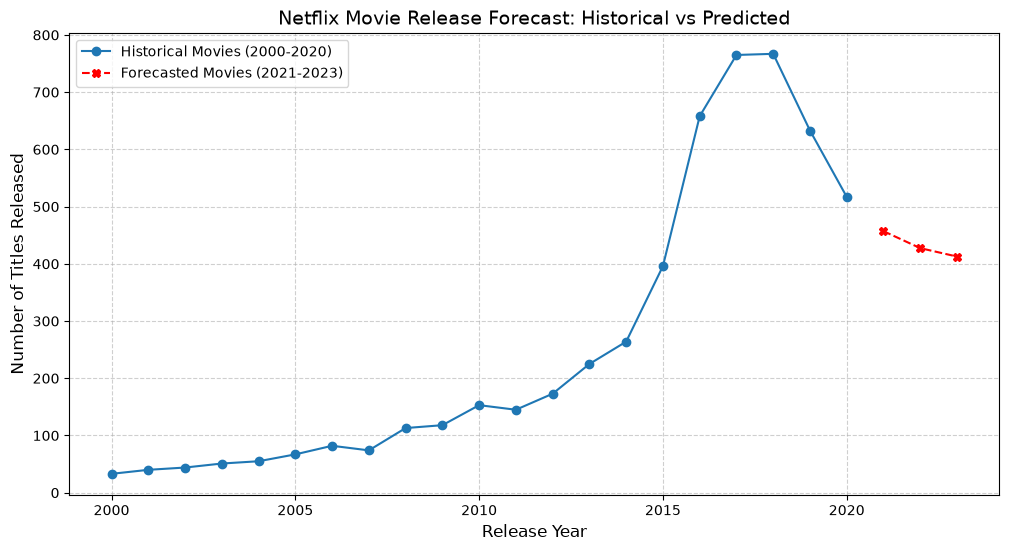

In [4]:
import matplotlib.pyplot as plt

# 1. Create a plot
plt.figure(figsize=(12, 6))

# 2. Plot Historical Data
plt.plot(movie_series.index, movie_series.values, label='Historical Movies (2000-2020)', marker='o')

# 3. Plot Forecasted Data (Years 2021, 2022, 2023)
future_years = [2021, 2022, 2023]
plt.plot(future_years, forecast.values, label='Forecasted Movies (2021-2023)', marker='X', color='red', linestyle='--')

# 4. Styling
plt.title('Netflix Movie Release Forecast: Historical vs Predicted', fontsize=14)
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Number of Titles Released', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [5]:
# 1. Prepare the TV Show data
tv_series = yearly_counts_clean['TV Show']

# 2. Train the ARIMA model for TV Shows
model_tv = ARIMA(tv_series, order=(1, 1, 1))
model_fit_tv = model_tv.fit()

# 3. Forecast the next 3 years (2021, 2022, 2023)
forecast_tv = model_fit_tv.forecast(steps=3)
print("Forecasted TV Shows for 2021, 2022, 2023:")
print(forecast_tv)

Forecasted TV Shows for 2021, 2022, 2023:
21    473.650323
22    508.692440
23    541.307033
Name: predicted_mean, dtype: float64


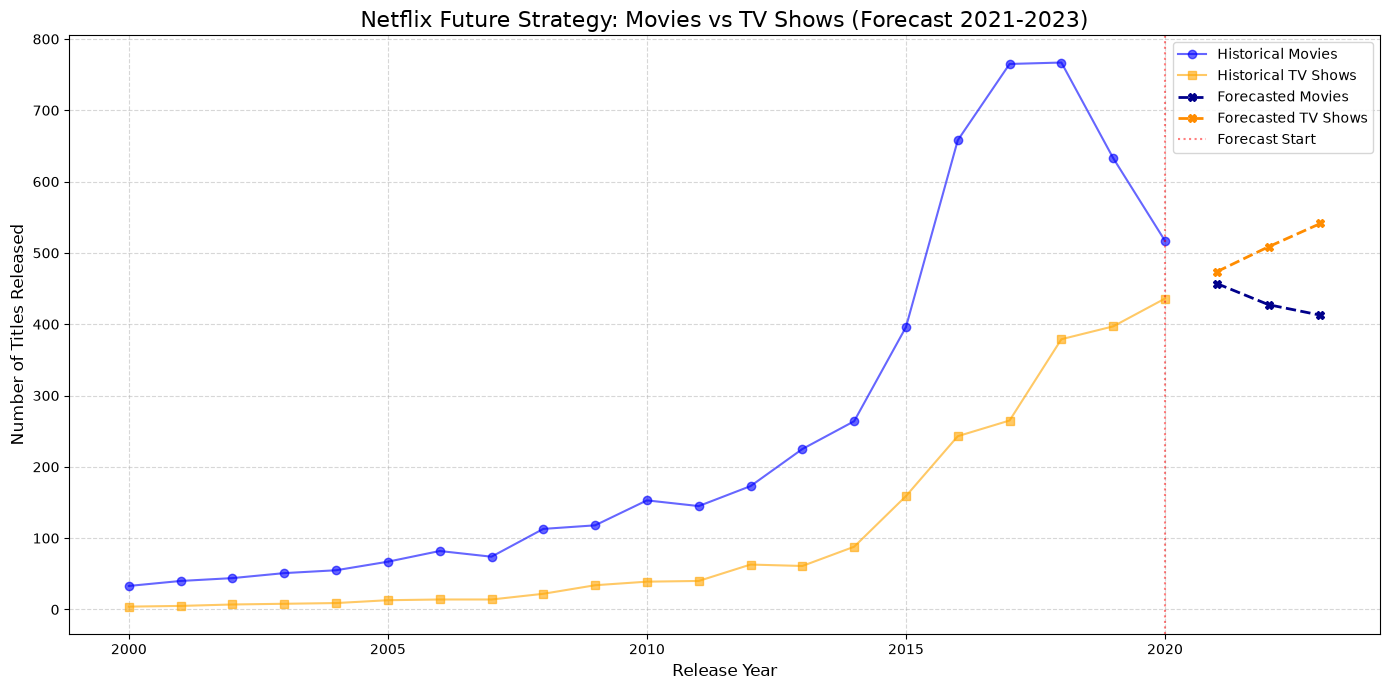

In [6]:
# 1. Create a bigger plot
plt.figure(figsize=(14, 7))

# --- HISTORICAL DATA ---
plt.plot(yearly_counts_clean.index, yearly_counts_clean['Movie'], label='Historical Movies', marker='o', color='blue', alpha=0.6)
plt.plot(yearly_counts_clean.index, yearly_counts_clean['TV Show'], label='Historical TV Shows', marker='s', color='orange', alpha=0.6)

# --- FORECASTED DATA ---
future_years = [2021, 2022, 2023]
plt.plot(future_years, forecast.values, label='Forecasted Movies', marker='X', color='darkblue', linestyle='--', linewidth=2)
plt.plot(future_years, forecast_tv.values, label='Forecasted TV Shows', marker='X', color='darkorange', linestyle='--', linewidth=2)

# 2. Add styling
plt.title('Netflix Future Strategy: Movies vs TV Shows (Forecast 2021-2023)', fontsize=16)
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Number of Titles Released', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

# 3. Add a vertical line to show where the forecast begins
plt.axvline(x=2020, color='red', linestyle=':', alpha=0.5, label='Forecast Start')
plt.legend()

plt.tight_layout()
plt.show()